In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


import warnings
import shap

from scipy.stats import loguniform, randint, uniform

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv('online_shoppers.csv')
pd.set_option('display.max_columns', None)

df.head(5)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
print("INFORMATION")
print(df.info())

print(50*"=")

print("GENERAL SUMMARY")
print(df.describe())

print(50*"=")

print("NULL VALUES")
print(df.isnull().sum())

print(50*"=")

print("DUPLICATE VALUES")
print(df.duplicated().sum())

print("DISTRIBUTION OF TARGET VALUE")
print(df['Revenue'].value_counts())
print(f"Percent of target value 'Yes': {round(df['Revenue'].mean() * 100, 2)}")

INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficTyp

In [4]:
print(df[df.duplicated(keep=False)])

print(df[df.duplicated()]['Revenue'].value_counts())

       Administrative  Administrative_Duration  Informational  \
85                  0                      0.0              0   
132                 0                      0.0              0   
158                 0                      0.0              0   
159                 0                      0.0              0   
178                 0                      0.0              0   
...               ...                      ...            ...   
11934               0                      0.0              0   
11938               0                      0.0              0   
12159               0                      0.0              0   
12180               0                      0.0              0   
12185               0                      0.0              0   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
85                        0.0               1                      0.0   
132                       0.0               1                      0.0 

In [5]:
page_pair = [
    ('Administrative', 'Administrative_Duration'),
    ('Informational', 'Informational_Duration'),
    ('ProductRelated', 'ProductRelated_Duration')
]

inconsistencies = 0

for page, dur in page_pair:
    cond1 = (df[page] == 0) & (df[dur] > 0)
    cond2 = (df[page] > 0) & (df[dur] == 0)

    cond1_count = cond1.sum()
    cond2_count = cond2.sum()
    incost_count = (cond1 | cond2).sum()

    inconsistencies += incost_count

    print(f'For {page} and {dur}:')
    print(f'Cond 1 Count: {cond1_count}')
    print(f'Cond 2 Count: {cond2_count}')
    print(f'Total Inconsistency: {incost_count}\n')

print(f'Overall Amount of Inconsistency: {inconsistencies}')

For Administrative and Administrative_Duration:
Cond 1 Count: 0
Cond 2 Count: 135
Total Inconsistency: 135

For Informational and Informational_Duration:
Cond 1 Count: 0
Cond 2 Count: 226
Total Inconsistency: 226

For ProductRelated and ProductRelated_Duration:
Cond 1 Count: 0
Cond 2 Count: 717
Total Inconsistency: 717

Overall Amount of Inconsistency: 1078


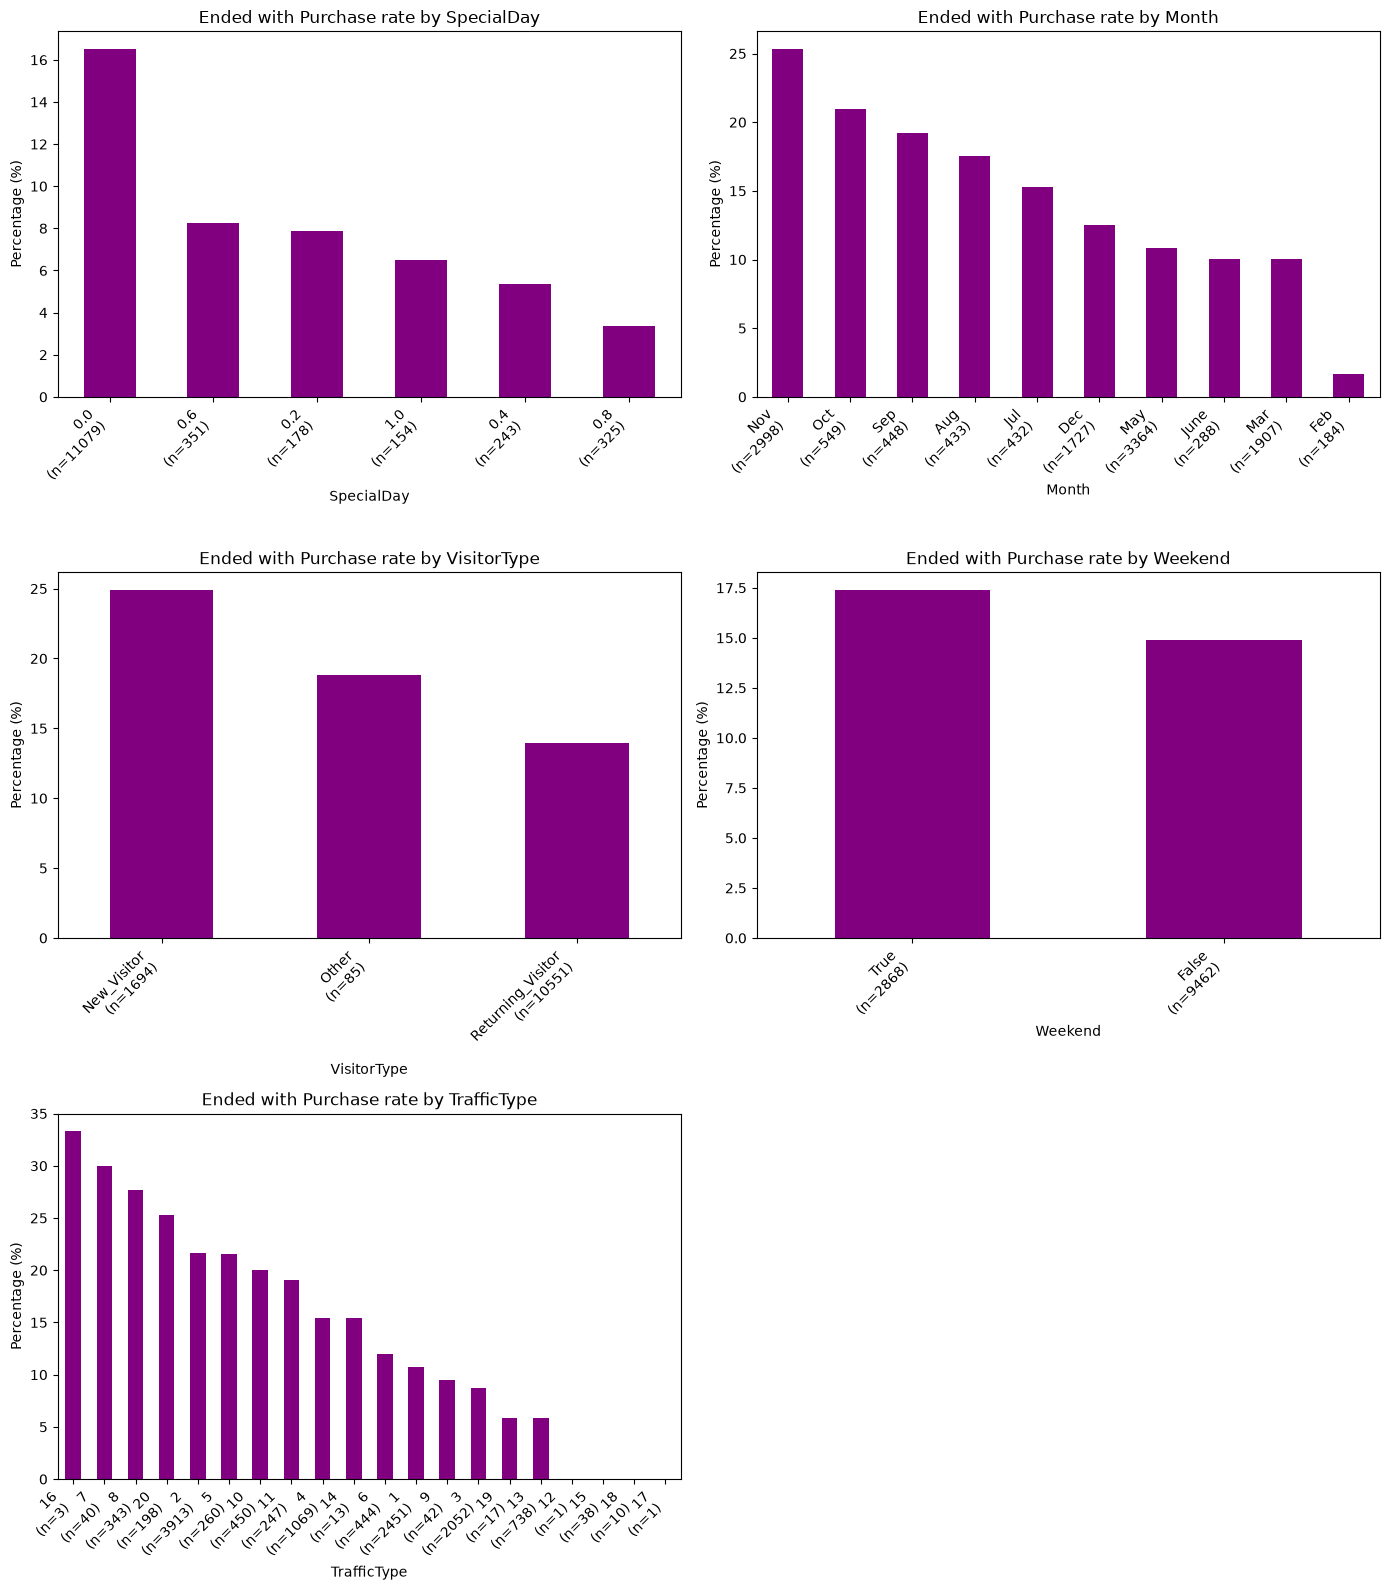

In [6]:
cols1 = ['SpecialDay', 'Month', 'VisitorType', 'Weekend', 'TrafficType']

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(cols1):
    col_sum = df.groupby(col)['Revenue'].agg(mean_rate = lambda x: x.mean() * 100, count='count').sort_values(by='mean_rate', ascending=False)

    col_sum['mean_rate'].plot(kind='bar', ax=axes[i], color='purple')

    labels = [f'{cat}\n(n={count})' for cat, count in zip(col_sum.index, col_sum['count'])]
    axes[i].set_xticks(range(len(col_sum)))
    axes[i].set_xticklabels(labels, rotation=45, ha='right')

    axes[i].set_title(f'Ended with Purchase rate by {col}')
    axes[i].set_ylabel('Percentage (%)')

fig.delaxes(axes[5])

plt.tight_layout()
fig.savefig('box-hist-intention', dpi=300, bbox_inches='tight')
plt.show()

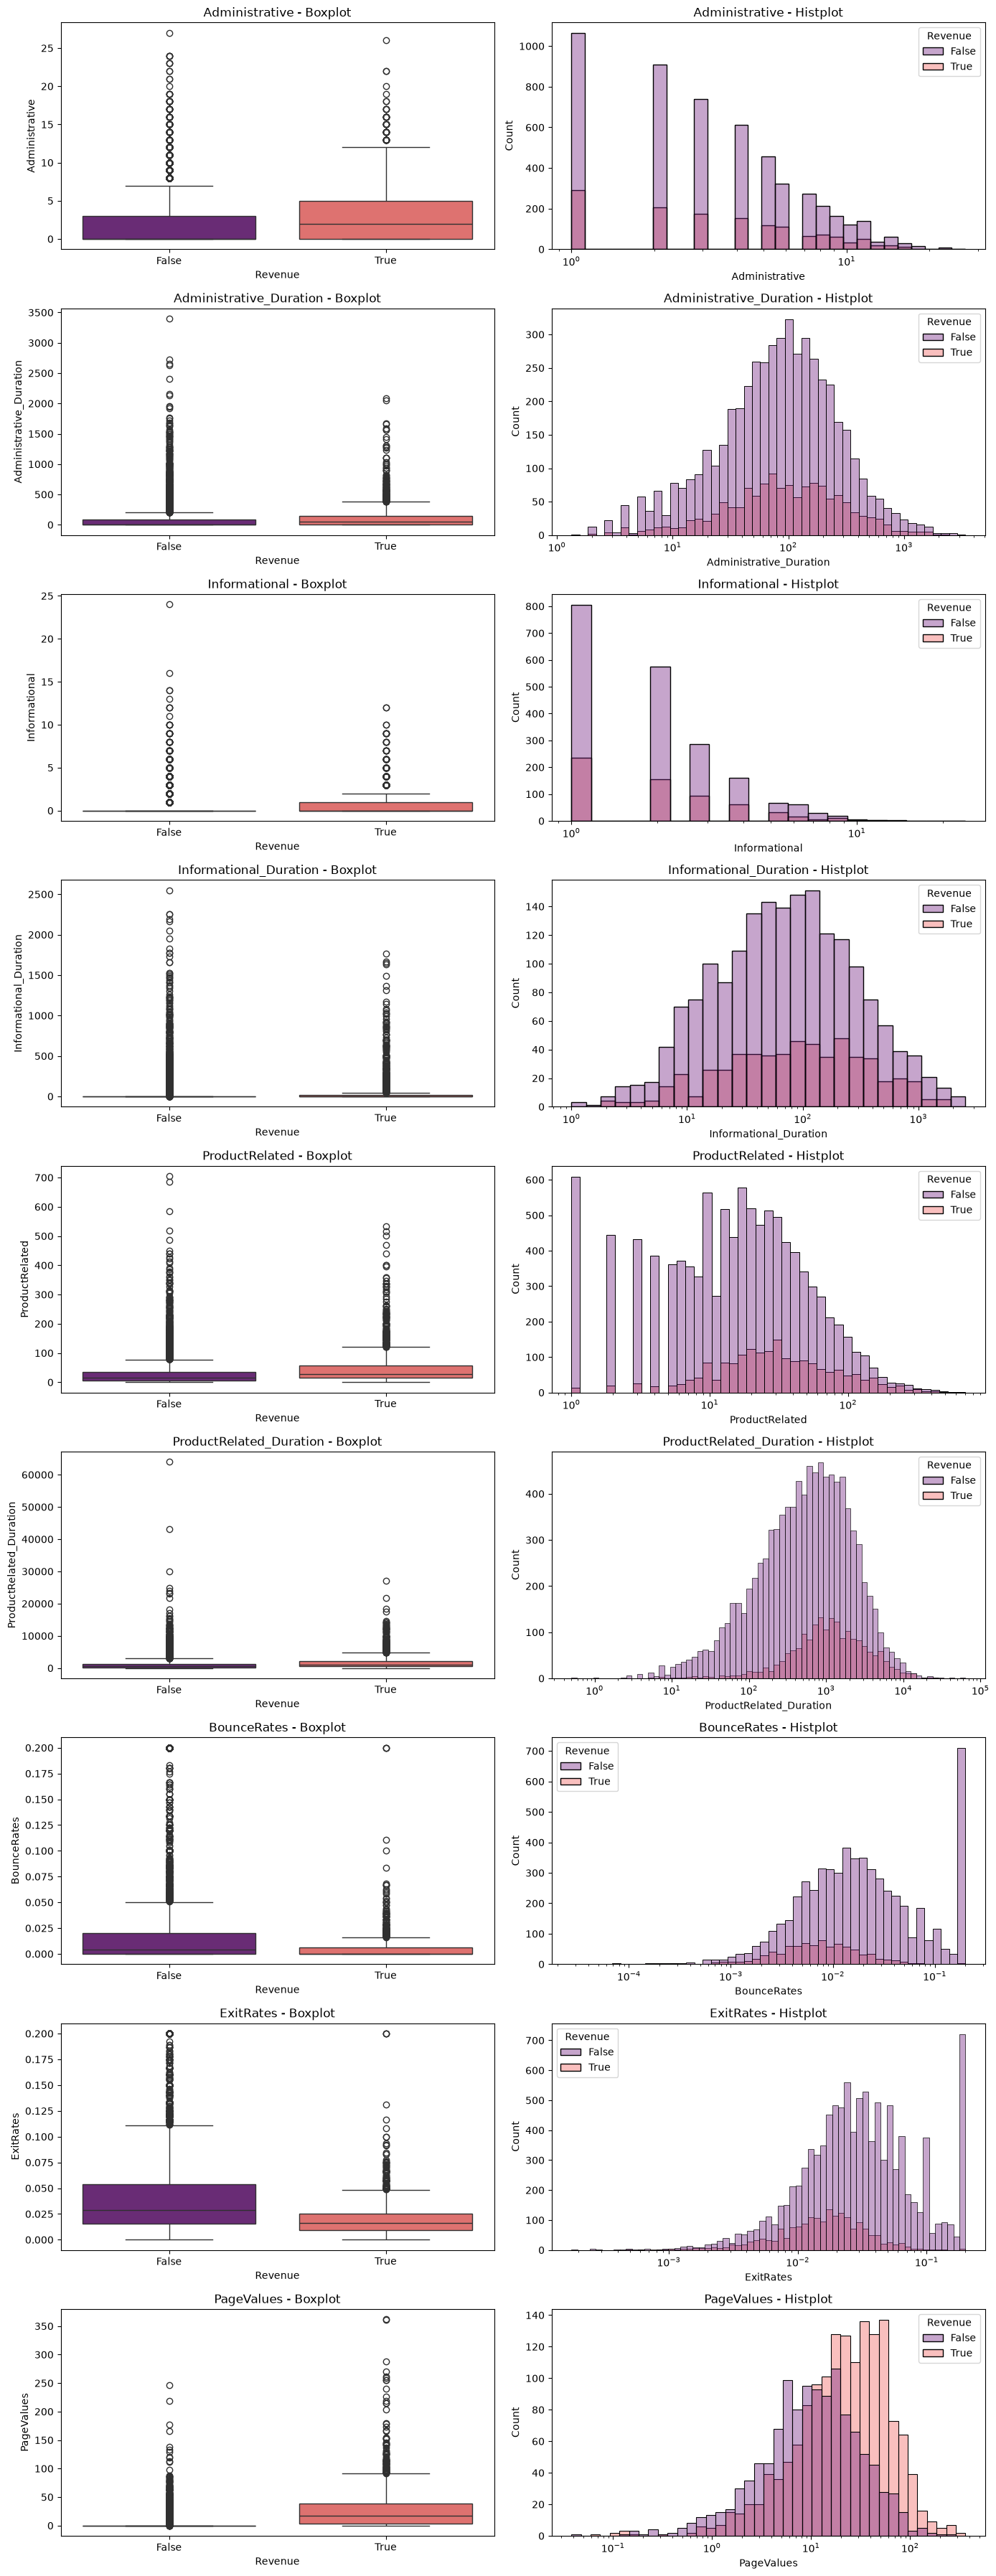

In [7]:
cols2 = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 
         'BounceRates', 'ExitRates', 'PageValues']

fig, axes = plt.subplots(nrows=9, ncols=2, figsize=(14, 36))

for i, col in enumerate(cols2):
    sns.boxplot(x='Revenue', y=col, hue='Revenue', data=df, ax=axes[i, 0], palette='magma', legend=False)
    axes[i, 0].set_title(f'{col} - Boxplot')
    axes[i, 0].set_xlabel('Revenue')
    axes[i, 0].set_ylabel(col)

    sns.histplot(data=df, x=col, hue='Revenue', log_scale=True, ax=axes[i, 1], palette='magma', common_norm=False, alpha=0.4)
    axes[i, 1].set_title(f'{col} - Histplot')
    axes[i, 1].set_xlabel(col)
    axes[i, 1].set_ylabel('Count')

plt.tight_layout()
fig.savefig('box-hist-intention2', dpi=150, bbox_inches='tight')
plt.show()

<Axes: >

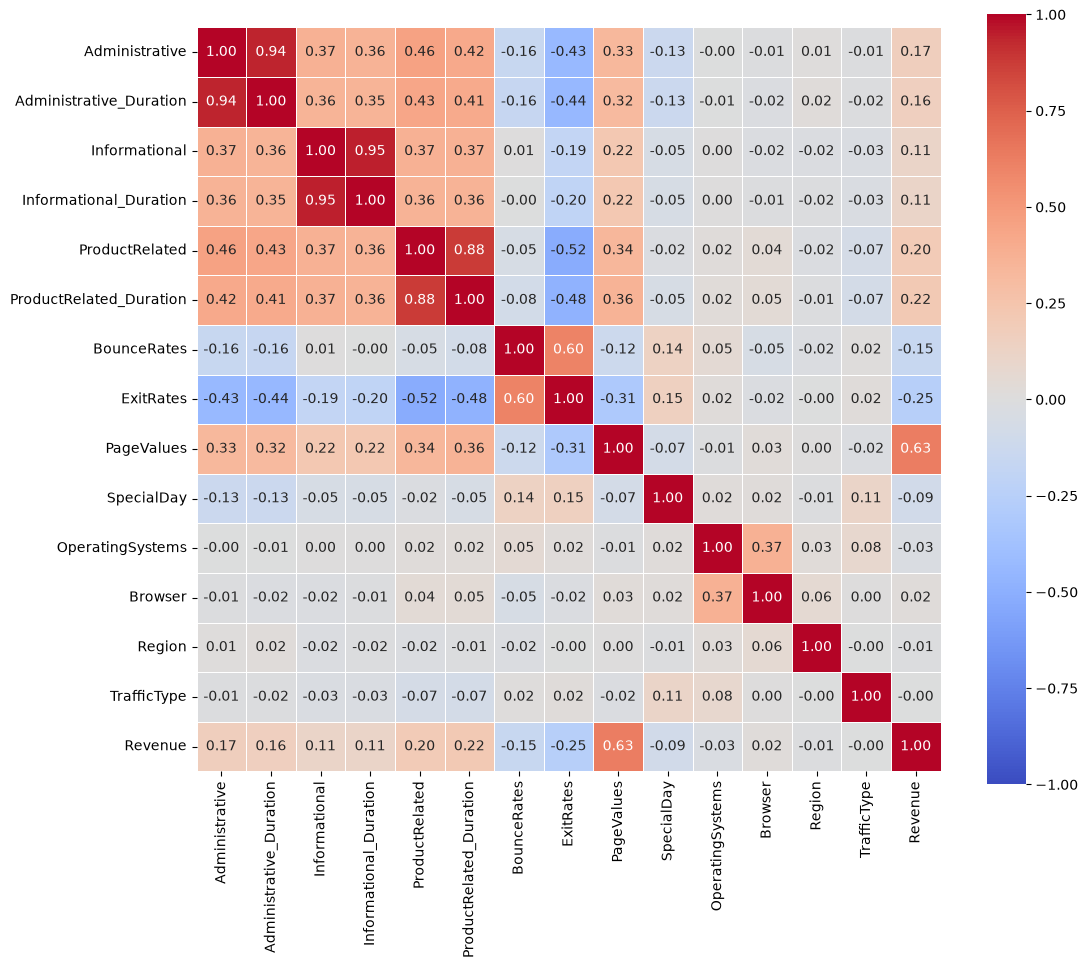

In [8]:
num_cols = df.select_dtypes(include=['number'])
num_cols['Revenue'] = df['Revenue'].astype(int)

corr_matrix = num_cols.corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, cbar=True, square=True, vmin=-1, vmax=1)

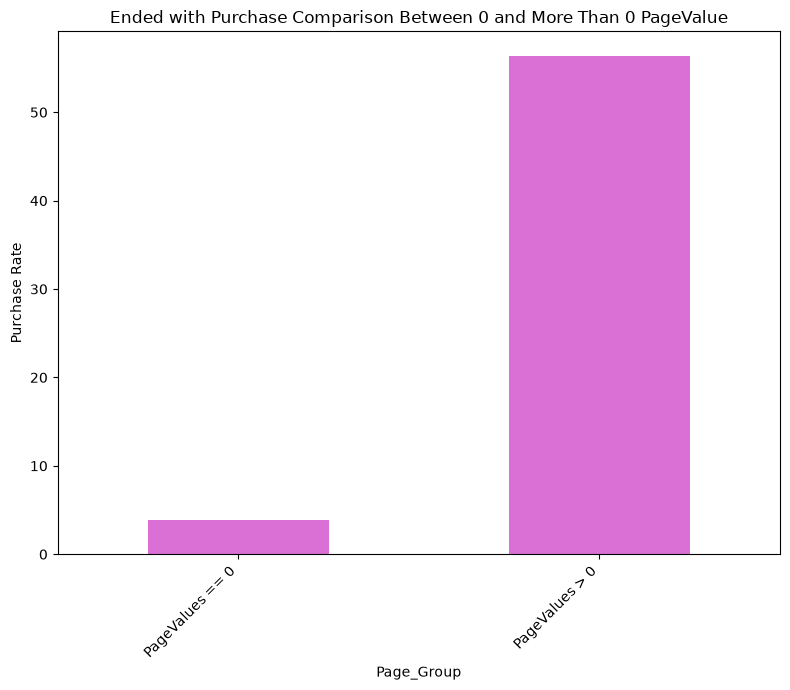

In [9]:
page_plot = df.copy()
page_plot['Page_Group'] = page_plot['PageValues'].apply(lambda x: 'PageValues == 0' if x == 0 else 'PageValues > 0')
group_revenue = page_plot.groupby('Page_Group')['Revenue'].mean() * 100

plt.figure(figsize=(8,7))
group_revenue.plot(kind='bar', color='orchid')
plt.title('Ended with Purchase Comparison Between 0 and More Than 0 PageValue')
plt.ylabel('Purchase Rate')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [10]:
pd.crosstab(df['Month'], df['SpecialDay'] > 0)

SpecialDay,False,True
Month,,
Aug,433,0
Dec,1727,0
Feb,105,79
Jul,432,0
June,288,0
Mar,1907,0
May,2192,1172
Nov,2998,0
Oct,549,0


In [11]:
df1 = df.drop_duplicates().reset_index(drop=True).copy()

X = df1.drop(columns='Revenue')
y = df1['Revenue'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y.mean(), y_train.mean(), y_test.mean())

(9764, 17) (2441, 17)
0.15632937320770177 0.15628840639082342 0.15649324047521507


In [12]:
num_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
cat_cols = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
boolean_cols = ['Weekend']
log_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
            'PageValues']
no_log_cols = ['BounceRates', 'ExitRates', 'SpecialDay']


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), cat_cols),
        ('bool', 'passthrough', boolean_cols)
    ]
)

preprocessor_log = ColumnTransformer(
    transformers=[
        ('log', Pipeline([
            ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
            ('scale', StandardScaler())
        ]), log_cols),
        ('num', StandardScaler(), no_log_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), cat_cols),
        ('bool', 'passthrough', boolean_cols)
    ]
)

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['precision', 'recall', 'f1', 'average_precision']
warnings.filterwarnings("ignore")

models = {
    'dummy':Pipeline([('prep', preprocessor), ('model', DummyClassifier(strategy='most_frequent'))]),
    'logreg':Pipeline([('prep', preprocessor_log), ('model', LogisticRegression(class_weight='balanced', max_iter=1000))]),
}

rows = {}
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {}
    for score in scoring:
        mean_val = scores[f'test_{score}'].mean()
        std_val = scores[f'test_{score}'].std()
        rows[name][score] = f'{mean_val:.3f} ± {std_val:.3f}'

results = pd.DataFrame(rows).T
results

,precision,recall,f1,average_precision
dummy,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.156 ± 0.000
logreg,0.545 ± 0.015,0.796 ± 0.020,0.647 ± 0.014,0.663 ± 0.023


In [14]:
tree_models = {
    'random_forest': Pipeline([
        ('prep', preprocessor),
        ('model', RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', min_samples_leaf=5, n_jobs=-1, random_state=42))
    ]),
    'gradient': Pipeline([
        ('prep', preprocessor),
        ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=42))
    ]),
}

for name, pipeline in tree_models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {}
    for score in scoring:
        mean_val = scores[f'test_{score}'].mean()
        std_val = scores[f'test_{score}'].std()
        rows[name][score] = f'{mean_val:.3f} ± {std_val:.3f}'

tree_results = pd.DataFrame(rows).T
tree_results

,precision,recall,f1,average_precision
dummy,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.156 ± 0.000
logreg,0.545 ± 0.015,0.796 ± 0.020,0.647 ± 0.014,0.663 ± 0.023
random_forest,0.599 ± 0.016,0.773 ± 0.021,0.675 ± 0.012,0.734 ± 0.017
gradient,0.589 ± 0.019,0.786 ± 0.021,0.673 ± 0.014,0.743 ± 0.019


In [15]:
gradient_pipe = Pipeline([('prep', preprocessor), ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=42))])

param_dist = {
    'model__learning_rate': loguniform(0.01, 0.3),
    'model__max_iter': randint(100, 500),
    'model__max_leaf_nodes': randint(8, 64),
    'model__min_samples_leaf': randint(10, 100),
    'model__l2_regularization': loguniform(1e-3, 10),
}

best_parameter = RandomizedSearchCV(gradient_pipe, param_dist, n_iter=30, cv=cv, scoring=scoring, refit='average_precision', n_jobs=-1, random_state=42)
best_parameter.fit(X_train, y_train)

print(best_parameter.best_params_)
print(f'Best AP: {best_parameter.best_score_:.3f}')

{'model__l2_regularization': np.float64(1.0524574681335637), 'model__learning_rate': np.float64(0.021775224101934068), 'model__max_iter': 259, 'model__max_leaf_nodes': 14, 'model__min_samples_leaf': 68}
Best AP: 0.753


In [16]:
gradient_params = {param.split('__', 1)[1]: value for param, value in best_parameter.best_params_.items()}
num_cols_nopage = [col for col in num_cols if col != 'PageValues']

preprocessor_nopage = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols_nopage),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), cat_cols),
        ('bool', 'passthrough', boolean_cols)
    ]
)

comparison = {'with PageValues': preprocessor, 'without PageValues': preprocessor_nopage}
compare = {}

for name, prep in comparison.items():
    pipe = Pipeline([('prep', prep), ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=42, **gradient_params))])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    compare[name] = {}
    for score in scoring:
        mean_val = scores[f'test_{score}'].mean()
        std_val = scores[f'test_{score}'].std()
        compare[name][score] = f'{mean_val:.3f} ± {std_val:.3f}'

comparison_results = pd.DataFrame(compare).T
comparison_results

,precision,recall,f1,average_precision
with PageValues,0.532 ± 0.016,0.842 ± 0.015,0.652 ± 0.014,0.753 ± 0.018
without PageValues,0.291 ± 0.010,0.749 ± 0.015,0.419 ± 0.012,0.378 ± 0.022


The Best Threshold: 0.722
Precision 0.664 | Recall 0.729 | F1 0.695


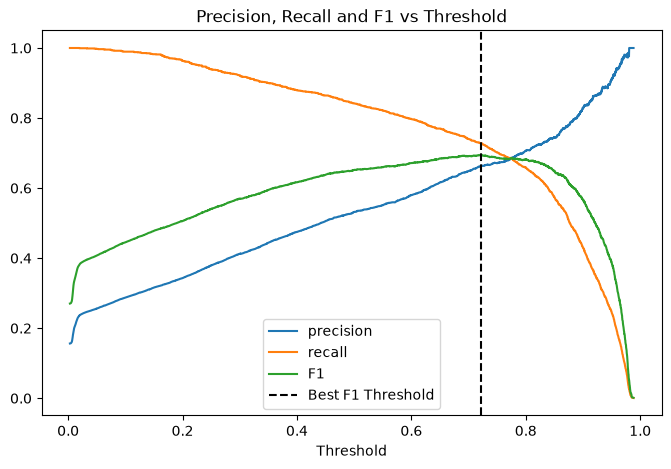

In [17]:
final_pipe = Pipeline([('prep', preprocessor), ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=42, **gradient_params))])

scores = cross_val_predict(final_pipe, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, scores)

f1 = 2 * precision * recall / (precision + recall + 1e-12)
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

print(f"The Best Threshold: {best_threshold:.3f}")
print(f"Precision {precision[best]:.3f} | Recall {recall[best]:.3f} | F1 {f1[best]:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label='precision')
plt.plot(thresholds, recall[:-1], label='recall')
plt.plot(thresholds, f1[:-1], label='F1')
plt.axvline(best_threshold, color='black', linestyle='--', label='Best F1 Threshold')
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision, Recall and F1 vs Threshold')
plt.show()

Precision: 0.647
Recall: 0.733
F1: 0.687
Average Precision: 0.755


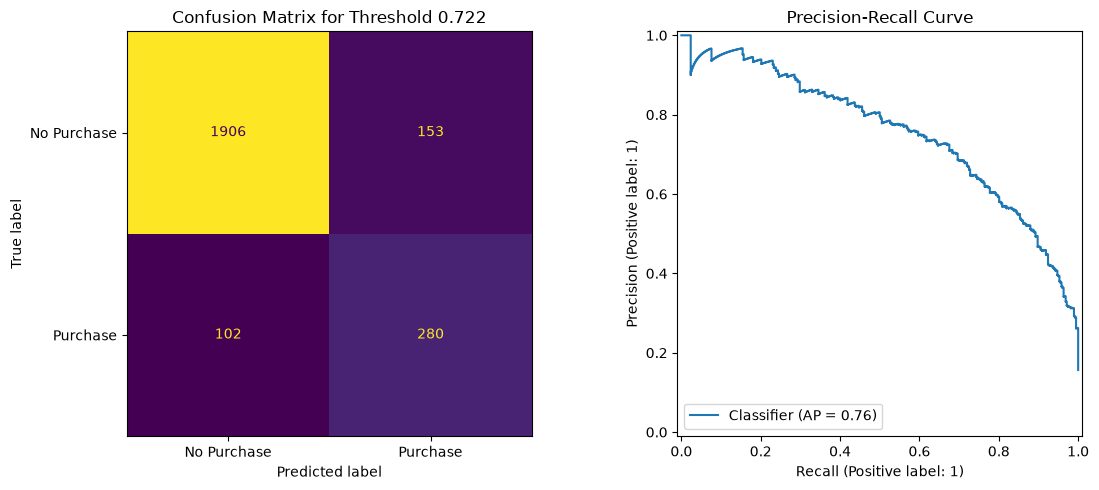

In [18]:
threshold = 0.722

final_pipe.fit(X_train, y_train)

test_scores = final_pipe.predict_proba(X_test)[:, 1]
test_prediction = (test_scores >= threshold).astype(int)

print(f"Precision: {precision_score(y_test, test_prediction):.3f}")
print(f"Recall: {recall_score(y_test, test_prediction):.3f}")
print(f"F1: {f1_score(y_test, test_prediction):.3f}")
print(f"Average Precision: {average_precision_score(y_test, test_scores):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_prediction), display_labels=['No Purchase', 'Purchase']).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f'Confusion Matrix for Threshold 0.722')
PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[1])
axes[1].set_title('Precision-Recall Curve')
plt.tight_layout()
plt.show()

                    feature  perf   std
8                PageValues  0.55  0.01
10                    Month  0.05  0.01
6               BounceRates  0.02  0.01
7                 ExitRates  0.02  0.01
0            Administrative  0.01  0.00
1   Administrative_Duration  0.01  0.00
4            ProductRelated  0.01  0.00
15              VisitorType  0.01  0.00
5   ProductRelated_Duration  0.01  0.00
3    Informational_Duration -0.00  0.00
14              TrafficType  0.00  0.00
11         OperatingSystems  0.00  0.00
13                   Region  0.00  0.00
16                  Weekend  0.00  0.00
2             Informational  0.00  0.00
9                SpecialDay  0.00  0.00
12                  Browser  0.00  0.00


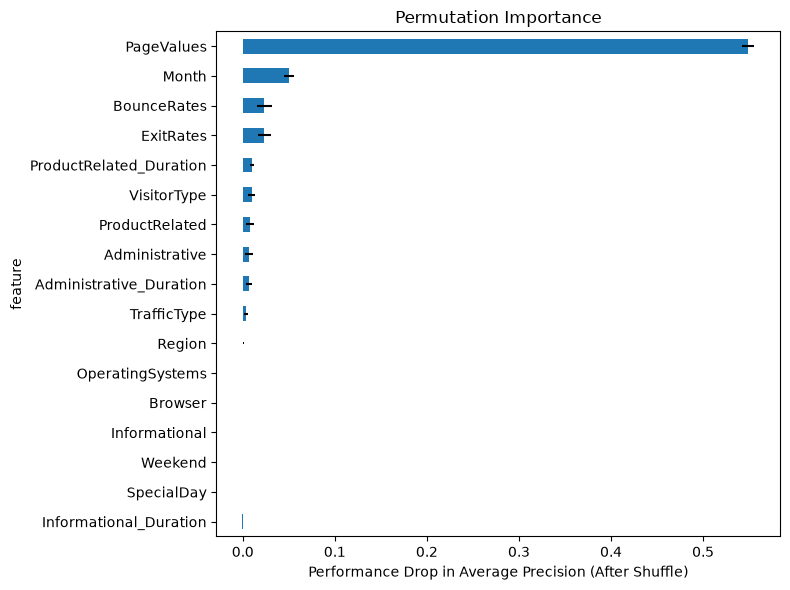

In [19]:
result = permutation_importance(final_pipe, X_test, y_test, scoring='average_precision', n_repeats=10, random_state=42, n_jobs=-1)

importance = pd.DataFrame({'feature':X_test.columns, 'perf':result.importances_mean, 'std':result.importances_std}).sort_values('perf', ascending=True)

print(importance.round(2).sort_values(by='perf', ascending=False))

importance.plot.barh(x='feature', y='perf', xerr='std', legend=False, figsize=(8,6))
plt.xlabel('Performance Drop in Average Precision (After Shuffle)')
plt.title('Permutation Importance')
plt.tight_layout()
plt.show()

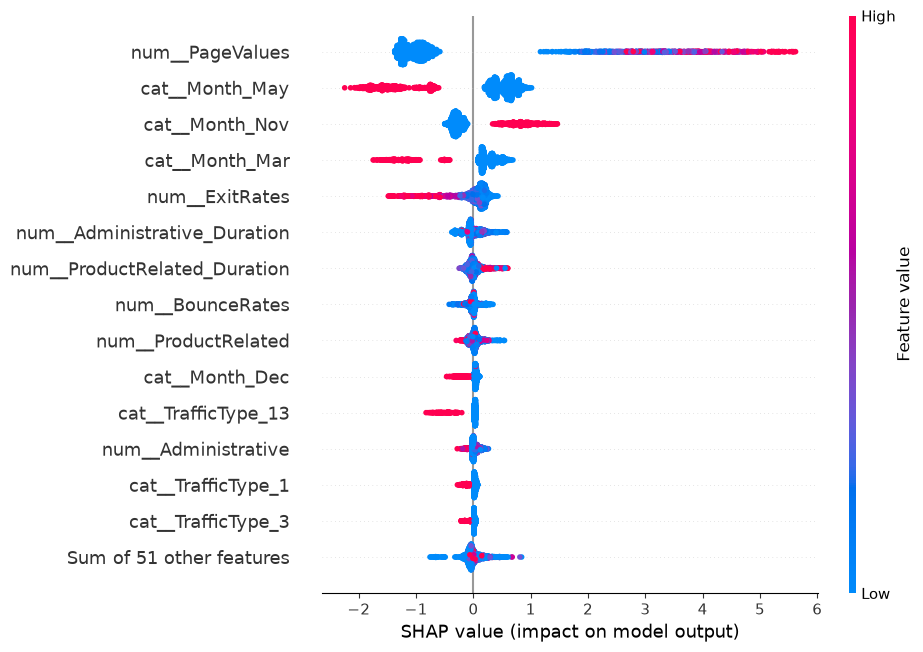

In [20]:
prep = final_pipe.named_steps['prep']
model = final_pipe.named_steps['model']

X_test_prep = pd.DataFrame(prep.transform(X_test), columns=prep.get_feature_names_out(), index=X_test.index)

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_prep)

shap.plots.beeswarm(shap_values, max_display=15)